> **Model answers.** This is the worked-solution copy of `09-probability-rules.ipynb`. Answers are marked ✅; code cells have been run so you can compare outputs.

# probability rules: "not", "or", "at least one" [P1]

Fixes two very common mistakes: adding P(A) + P(B) without subtracting the overlap, and not knowing the complement trick.

## Lesson notes

**Plain English:** a probability is how likely something is, on a scale from **0** (never happens) to **1** (certain). You can write the same probability three ways: 0.25 = 25% = "1 in 4". (Why they match: 1 ÷ 4 = 0.25, and 0.25 × 100 = 25%, because "per cent" means "out of 100".)

**From counts to a probability:** when you have counts of people (or transactions, or complaints), the probability that a randomly picked one is in a group is

P(group) = (number in the group) ÷ (total number)

| Count out of 1,000 | Divide by 1,000 | As a % |
|---|---|---|
| 300 | 300 ÷ 1,000 = **0.30** | 30% |
| 80 | 80 ÷ 1,000 = **0.08** | 8% |
| 420 | 420 ÷ 1,000 = **0.42** | 42% |

**Tip:** you can do all the working in **counts** and only divide by the total at the very end. You get the same answer, and it's easier to see what's going on.

**Notation (every symbol you'll see):**

| Symbol | Say it | Means |
|---|---|---|
| P(A) | "P of A" | probability that event A happens |
| P(not A), also written Aᶜ ("A complement") | "P of not A" | probability A does **not** happen |
| P(A or B), also written A ∪ B ("A union B") | "A or B" | **at least one** of A, B happens: A only, B only, **or both** |
| P(A and B), also written A ∩ B ("A intersect B") | "A and B" | **both** happen: the overlap |

**Careful: "or" in probability is not everyday "or".**
- In everyday English, "or" often means **one or the other but not both**: "do you want tea or coffee?" expects one drink.
- In probability (and in maths, Python and SQL), **"or" always includes "both"**. "Has a card or a loan" counts card only, loan only **and** customers with both.
- If a question means "one but not both", it will say so: "**exactly one**" or "**only** one". That's a different number (in the example below: card only 220 + loan only 120 = 340 customers, not 420, because the 80 with both are left out).

**Rule 1: complement ("not").** Every customer either is in a group or isn't, so the two probabilities add up to 1 (everyone):

P(not A) = 1 − P(A)

Example: P(loan defaults) = 0.04, so P(doesn't default) = 1 − 0.04 = **0.96**. In counts: out of 1,000 loans, 40 default, so 1,000 − 40 = 960 don't, and 960 ÷ 1,000 = 0.96.

**Rule 2: "or" = add, then subtract the overlap.**

P(A or B) = P(A) + P(B) − P(A and B)

Below, we build this up from the counts one step at a time, so you can see where every number comes from.

**Worked example: what you're given.** 1,000 bank customers:
- **300** have a credit card (call this event C)
- **200** have a loan (event L)
- **80** have **both** a card and a loan

**The key thing to notice:** the 300 is *everyone* with a card, and that **includes** the 80 who also have a loan. Likewise the 200 is everyone with a loan, and that **includes** the same 80. So the 300 and the 200 are **not** separate groups: they share 80 people.

**Step 1: split everyone into four groups that don't overlap.** Use subtraction:

| Group | How to get it | Count |
|---|---|---|
| Card **and** loan (both) | given | **80** |
| Card **only** (card, no loan) | all card holders − those who also have a loan = 300 − 80 | **220** |
| Loan **only** (loan, no card) | all loan holders − those who also have a card = 200 − 80 | **120** |
| **At least one** (card or loan) | card only + both + loan only = 220 + 80 + 120 | **420** |
| **Neither** | everyone − at least one = 1,000 − 420 (rule 1) | **580** |

**Check:** the four groups that don't overlap must add up to everyone: 220 + 80 + 120 + 580 = **1,000** ✓.

**The four groups as a Venn diagram.** The box is all 1,000 customers. Each circle is one group, and the part where the circles cross is the overlap:

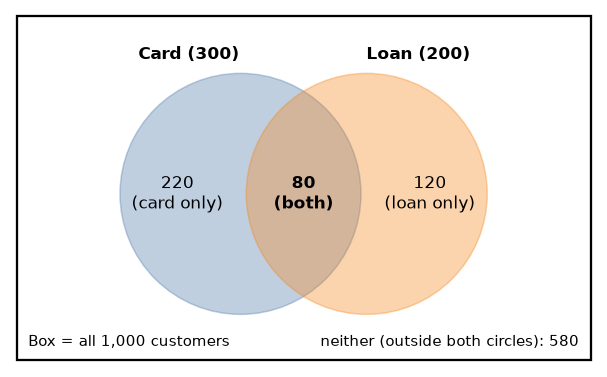

- **Card circle** = 220 + 80 = **300** (that's why the 300 "includes" the 80)
- **Loan circle** = 120 + 80 = **200**
- **Card or loan** = everything inside **either** circle = 220 + 80 + 120 = **420**
- **Neither** = inside the box but outside both circles = **580**

**The same numbers as a table.** Each row and column adds up to its total. That's a good way to check your subtraction:

| | Loan | No loan | Row total |
|---|---|---|---|
| **Card** | 80 (both) | 220 (card only) | 80 + 220 = 300 ✓ |
| **No card** | 120 (loan only) | 580 (neither) | 120 + 580 = 700 |
| **Column total** | 80 + 120 = 200 ✓ | 220 + 580 = 800 | 1,000 |

**Step 2: turn the counts into probabilities** (divide each by the total, 1,000):

| Probability | Which group | Working | Value |
|---|---|---|---|
| P(C) | everyone with a card (card only + both) | 300 ÷ 1,000 | 0.30 |
| P(L) | everyone with a loan (loan only + both) | 200 ÷ 1,000 | 0.20 |
| **P(C and L)** | **the "both" group, the overlap** | **80 ÷ 1,000** | **0.08** |

**This 0.08 is the number the formula subtracts.** It is simply the "both" count turned into a probability.

**Step 3: use the formula, and see why the subtraction is there.**

P(C or L) = P(C) + P(L) − P(C and L) = 0.30 + 0.20 − 0.08 = **0.42**

Why subtract? Look at what each number covers, in counts:

| Number | Which people it counts |
|---|---|
| P(C) = 0.30 | card only (220) **+ both (80)** |
| P(L) = 0.20 | loan only (120) **+ both (80)** |
| P(C) + P(L) = 0.50 | 220 + 120 + **80 + 80** = 500 people: the "both" group has been counted **twice** |
| − P(C and L) = − 0.08 | takes the extra 80 off once: 500 − 80 = **420** people |

420 ÷ 1,000 = **0.42**, which matches Step 1 (card only + both + loan only = 420) ✓.

**In counts only** (often easier): 300 + 200 − 80 = 420, then 420 ÷ 1,000 = 0.42.

**When is the overlap zero? When the two things can't happen together.**

These are called **mutually exclusive** events. Examples:
- A single card payment is **approved** or **declined**. It can't be both.
- A customer's age band is "18–25" or "26–35". One person can't be in both.
- One roll of a die gives a 1 or a 6. It can't give both.

Then the "both" group is **empty**: P(A and B) = 0. The circles don't touch:

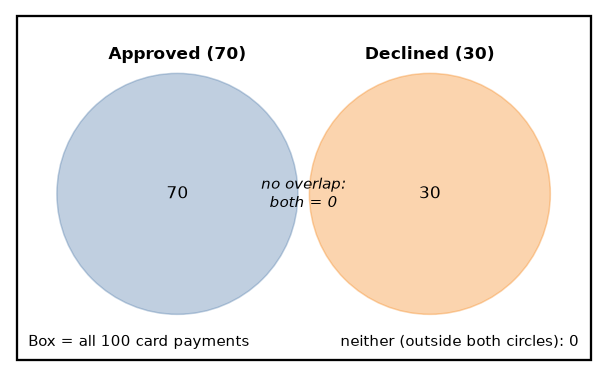

The formula still works, the subtraction is just 0: P(approved) = 70 ÷ 100 = 0.70 and P(declined) = 30 ÷ 100 = 0.30, so P(approved or declined) = 0.70 + 0.30 − **0** = 1.00. That makes sense: every payment is one or the other, so it is certain (1).

**So "or = just add" is not a different rule.** It's rule 2 with an overlap of 0. Whether you can just add depends on one question:

> **"Could one customer (or payment, or roll) be in both groups at the same time?"**
> - **No** → overlap = 0 → just add.
> - **Yes** (e.g. card and loan) → you **need the overlap number**, and you subtract it.

**Rule 3: "at least one" = 1 − P(none).**

**Why not count "at least one" directly? Because it covers lots of cases, and "none" is only one case.**

**How many patterns are there?** Each of the 5 transactions is either **flagged (F)** or **fine (✓)**: 2 options each. Every option for transaction 1 can go with every option for transaction 2, and so on, so the number of patterns is

2 × 2 × 2 × 2 × 2 = **32** patterns in total.

A few of them, written out (transactions 1 to 5):

| Pattern | How many flagged |
|---|---|
| ✓ ✓ ✓ ✓ ✓ | 0 ("none") |
| F ✓ ✓ ✓ ✓ | 1 |
| ✓ F ✓ ✓ ✓ | 1 |
| F F ✓ ✓ ✓ | 2 |
| F ✓ F ✓ F | 3 |
| F F F F F | 5 |
| … and 26 more | |

**Exactly one** pattern has nothing flagged: ✓ ✓ ✓ ✓ ✓. **Every other pattern** has at least one F, so:

"at least one flagged" = 32 − 1 = **31** patterns.

**Check by counting them group by group:**

| How many flagged | Number of patterns | Why |
|---|---|---|
| exactly 1 | 5 | the one F can be on transaction 1, 2, 3, 4 or 5 |
| exactly 2 | 10 | pairs: 1&2, 1&3, 1&4, 1&5, 2&3, 2&4, 2&5, 3&4, 3&5, 4&5 |
| exactly 3 | 10 | choosing 3 to flag = choosing the 2 to leave fine, so the same as the pairs |
| exactly 4 | 5 | choosing the 1 to leave fine: 5 options |
| exactly 5 | 1 | F F F F F |
| **total** | 5 + 10 + 10 + 5 + 1 = **31** ✓ | |

Working out the probability of 31 patterns and adding them up is slow. Working out the **one** "none" pattern is quick. So: **work out P(none), then use rule 1:** P(at least one) = 1 − P(none).

**First, a new rule you need: "and" for independent events = multiply.**

**Independent** means one event doesn't change the chance of the other. Examples:
- Independent: whether one transaction is wrongly flagged doesn't change the chance for the customer's next transaction (that's what we assume about the model here).
- **Not** independent: a customer missing a payment and the same customer defaulting. One makes the other much more likely.

**Why multiply? Think in counts.** 10,000 customers each make 2 transactions. Each transaction has a 2% chance of being flagged, so (rule 1) a 100% − 2% = **98%** chance of **not** being flagged.

| Step | Working | Customers |
|---|---|---|
| Start | | 10,000 |
| 1st transaction not flagged | 98% of 10,000 = 10,000 × 0.98 | 9,800 |
| 2nd also not flagged | 98% **of those 9,800** = 9,800 × 0.98 | 9,604 |

P(both not flagged) = 9,604 ÷ 10,000 = 0.9604, and that's exactly 0.98 × 0.98. **"Of those" is the multiplication.** Independence is what lets us use the same 98% at the second step.

**Rule: if A and B are independent, P(A and B) = P(A) × P(B).**

**Worked example:** a fraud model wrongly flags each normal transaction with probability 0.02, independently. A customer makes 5 transactions. What's the chance at least one gets flagged?

| Step | What it means | Working | Result |
|---|---|---|---|
| 1 | P(one transaction **not** flagged) | 1 − 0.02 (rule 1) | 0.98 |
| 2 | P(**none** of the 5 flagged): all five "not flagged", independent, so multiply | 0.98 → × 0.98 = 0.9604 → × 0.98 = 0.9412 → × 0.98 = 0.9224 → × 0.98 = 0.9039. Short way: 0.98⁵ ("0.98 to the power 5") | 0.9039 |
| 3 | P(**at least one** flagged) = everything except "none" | 1 − 0.9039 (rule 1 again) | **0.0961 ≈ 9.6%** |

**General formula:** P(at least one in n tries) = 1 − (1 − p)ⁿ, where p = the chance on **one** try and n = the number of tries. Read it as: (1 − p) is "doesn't happen once", ⁿ is "doesn't happen n times in a row", and 1 − … is "so it happens at least once".

**The trap: "5 × 2% = 10%".** It's close here (10% vs 9.6%), but try 60 transactions: 60 × 2% = 120%, which is **impossible**, because a probability can't go above 1 (100%). The right answer, using the formula: 0.98⁶⁰ = 0.2976 (calculator: 0.98, then the power key xʸ or ^, then 60), so 1 − 0.2976 = 0.7024 = **70.2%**.

**Why adding goes wrong: it's rule 2 again.** "Flagged on transaction 1" or "flagged on transaction 2" or … can **overlap**: a customer can be flagged on two or more transactions. Adding the 2%s counts those customers once for **every** flag, the same double-counting as the 80 "both" customers above. With few tries the overlaps are tiny, so the answer is nearly right. With many tries they pile up and you go past 100%.

**Traps to avoid:**
- **"Or" without subtracting the overlap.** Only safe when the events can't happen together (mutually exclusive), because then the overlap is 0.
- **Treating "card holders" (300) as "card only" (220).** The given totals include the overlap. Subtract it to get the "only" groups.
- **Reading "or" as "one but not both".** In probability, "or" includes both.
- **Multiplying for "and" when events are not independent.** Late payment and default for the same customer go together, so you can't just multiply.
- **Mutually exclusive ≠ independent.** If A and B can't both happen, knowing A happened tells you B didn't. So they're **dependent**, the opposite of independent.
- **Adding probabilities for "at least one".** Use 1 − P(none).

**Why ML cares:**
- **Fraud and alerts:** a 1% false-alarm rate per transaction becomes a large chance of annoying a customer who makes 100 payments: P(one payment not flagged) = 1 − 0.01 = 0.99; P(none of 100 flagged) = 0.99¹⁰⁰ = 0.366; so P(at least one) = 1 − 0.366 = 0.634 ≈ **63%**.
- **Multiple testing in A/B tests:** say you run 20 tests at a 5% false-positive rate (significance level α, "alpha" = 0.05) and none of the changes really works. Each test correctly says "nothing" with probability 1 − 0.05 = 0.95. P(all 20 say "nothing") = 0.95²⁰ = 0.358. So P(at least one "significant" result) = 1 − 0.358 = 0.642 ≈ **64%**. This is why teams correct for running many tests.
- **Retrieval-augmented generation (RAG):** if each of 5 retrieved documents is relevant with probability 0.6, P(one document **not** relevant) = 1 − 0.6 = 0.4; P(none of 5 relevant) = 0.4⁵ = 0.4 × 0.4 × 0.4 × 0.4 × 0.4 = 0.01024; so P(at least one relevant) = 1 − 0.01024 = 0.98976 ≈ **99%**. That's why retrieving several documents helps.

**Glossary:**
- **complement** = "not A", everything outside A.
- **union (∪)** = "or": at least one, **including both**.
- **intersection (∩)** = "and": both at once, the overlap.
- **exactly one / only one** = one but not both = P(A or B) − P(A and B).
- **mutually exclusive** = can't happen together, so the overlap is 0.
- **independent** = one doesn't change the chance of the other, so "and" = multiply.
- **A/B test** = an experiment comparing version A with version B.
- **α (alpha)** = significance level, the false-positive rate you accept.
- **RAG** = retrieval-augmented generation.

## Questions

Use a calculator where needed. Show your working: formula → numbers → answer.

**Q1 (easy).** A credit card application is rejected with probability 0.15. What is the probability it is **not** rejected? Which rule did you use?

✅ **Model answer**

P(not rejected) = 1 − 0.15 = **0.85**, using **rule 1, the complement**.

**Q2 (easy).** 500 complaints. 160 are about fees, 90 are about the app, 30 are about **both**.    
(a) What is the probability a random complaint is about fees **or** the app?    
(b) What is the probability it is about **neither**?

✅ **Model answer**

(a) P(fees or app) = 160/500 + 90/500 − 30/500 = 0.32 + 0.18 − 0.06 = **0.44** (220 complaints).
(b) P(neither) = 1 − P(fees or app) = 1 − 0.44 = **0.56** (280 complaints).

**Q3 (medium).**    
(a) A customer's main account is either "current" (probability 0.6) or "savings only" (probability 0.25), never both. What is P(current or savings only)? Why is no subtraction needed?    
(b) P(has a mortgage) = 0.3 and P(has a credit card) = 0.5. Can you work out P(mortgage or credit card) from just these two numbers? Say why or why not.

✅ **Model answer**

(a) 0.6 + 0.25 = **0.85**. No subtraction because the two **can't happen together** (mutually exclusive), so the overlap P(both) = 0.
(b) **No.** You need P(mortgage **and** credit card), the overlap. It could be anything from 0 (answer 0.8) up to 0.3 (answer 0.5). If you knew they were independent you could use 0.3 × 0.5 = 0.15 (answer 0.65), but nothing says they are.

**Q4 (medium).** A fraud model wrongly flags each normal transaction with probability 0.01, independently. A customer makes 10 transactions.    
(a) What is the probability at least one is flagged? Show all three steps.    
(b) A colleague says "10 × 1% = 10%". Use 150 transactions to show why that method is wrong.

✅ **Model answer**

(a) Step 1: P(one not flagged) = 1 − 0.01 = 0.99. Step 2: P(none of 10 flagged) = 0.99¹⁰ = 0.904. Step 3: P(at least one) = 1 − 0.904 = **0.096** (9.6%).
(b) "150 × 1% = 150%" is impossible, since a probability can't exceed 1. The right answer is 1 − 0.99¹⁵⁰ = 1 − 0.221 = **0.779**. Adding counts the cases with two or more flags several times over.

**Q5 (applied, interview-style).** "Our team ran 14 A/B tests last quarter, each at a 5% false-positive rate (α = 0.05). Suppose none of the 14 changes really does anything. What's the chance at least one test still came out 'significant'? What would you tell the product manager, and what assumption are you making?"

✅ **Model answer**

P(at least one false "significant") = 1 − 0.95¹⁴ = 1 − 0.488 = **0.512**, about **51%**.
"Even if none of the changes work, there's roughly a coin-flip chance that at least one of 14 tests looks like a winner. So one significant result out of 14 isn't strong evidence. Re-test the winner on fresh data, or correct for multiple testing (e.g. Bonferroni: use α = 0.05 / 14 ≈ 0.0036 per test)." **Assumption:** the 14 tests are **independent** (different users and changes), so the "no false positive" chances can be multiplied.

## Code it
Run the first cell, then fill every `TODO`.

In [1]:
%matplotlib inline
import numpy as np

### C1: `prob_or(p_a, p_b, p_both)`

**What you're building:** a function that returns P(A or B), the chance at least one of two events happens (rule 2).

**Inputs:**
- `p_a`: P(A), e.g. `0.30` (customer has a credit card)
- `p_b`: P(B), e.g. `0.20` (customer has a loan)
- `p_both`: P(A and B), the overlap, e.g. `0.08` (has both)

| Step | What it means | Code idea | Example result |
|---|---|---|---|
| 1 | add the two probabilities | `p_a + p_b` | 0.30 + 0.20 = 0.50 |
| 2 | subtract the overlap (it was counted twice) | `- p_both` | 0.50 − 0.08 = 0.42 |
| 3 | return it | `return ...` | 0.42 |

**Check:** `prob_or(0.30, 0.20, 0.08)` → `0.42` (Python may print 0.41999999999999993: that's normal decimal rounding, it's still 0.42).

In [2]:
def prob_or(p_a, p_b, p_both):
    return p_a + p_b - p_both

print("C1:", prob_or(0.30, 0.20, 0.08))   # expect 0.42

C1: 0.42


### C2: `prob_at_least_one(p, n)`

**What you're building:** a function that returns P(at least one happens in n independent tries), using rule 3: 1 − P(none).

**Inputs:**
- `p`: the chance on **one** try, e.g. `0.02` (one transaction wrongly flagged)
- `n`: the number of tries, e.g. `5` (transactions)

| Step | What it means | Code idea | Example result |
|---|---|---|---|
| 1 | chance one try does **not** happen | `1 - p` | 1 − 0.02 = 0.98 |
| 2 | chance **none** of the n happen (multiply n times) | `(1 - p) ** n` | 0.98⁵ = 0.9039 |
| 3 | chance **at least one** happens | `1 - ...` | 1 − 0.9039 = 0.0961 |

**Check:** `prob_at_least_one(0.02, 5)` → about `0.0961`. Also try `prob_at_least_one(0.02, 60)` → about `0.702`.

In [3]:
def prob_at_least_one(p, n):
    return 1 - (1 - p) ** n

print("C2:", prob_at_least_one(0.02, 5))   # expect about 0.0961
print("C2 (60):", prob_at_least_one(0.02, 60))   # about 0.702

C2: 0.09607920320000007
C2 (60): 0.7024468573078796


### C3: simulate it (check C2 with fake data)

**What you're building:** 100,000 pretend customers who each make 5 transactions. Each transaction is flagged with probability 0.02. Count what fraction of customers get **at least one** flag, and compare with C2.

**Inputs:**
- `rng`: a random-number generator (already made for you, seed 42 so everyone gets the same numbers)
- 100,000 customers, 5 transactions each, p = 0.02

| Step | What it means | Code idea | Example result |
|---|---|---|---|
| 1 | a grid of random numbers between 0 and 1: one row per customer, one column per transaction | `u = rng.random((100_000, 5))` | shape (100000, 5) |
| 2 | a transaction is "flagged" if its number is below 0.02 (happens 2% of the time) | `flags = u < 0.02` | True/False grid |
| 3 | did each customer get **any** flag? (look along each row) | `flags.any(axis=1)` | 100,000 True/False values |
| 4 | fraction of customers with at least one flag (True counts as 1) | `.mean()` | about 0.095 |
| 5 | print it next to C2's answer | `print(sim, prob_at_least_one(0.02, 5))` | 0.095 vs 0.0961 |

**Check:** the simulated value is within about 0.002 of 0.0961.

In [4]:
rng = np.random.default_rng(42)
u = rng.random((100_000, 5))
flags = u < 0.02
sim = flags.any(axis=1).mean()
print("C3:", sim, "vs exact", prob_at_least_one(0.02, 5))   # within ~0.002

C3: 0.09523 vs exact 0.09607920320000007


### C4: the multiple-testing table

**What you're building:** a small table showing how the chance of at least one false "significant" result grows as you run more A/B tests. **Reuse your C2 function, don't re-type the formula.**

**Inputs:**
- α (alpha) = `0.05`: the false-positive rate of each test
- numbers of tests: `[1, 5, 10, 14, 20, 50]`

| Step | What it means | Code idea | Example result |
|---|---|---|---|
| 1 | loop over the numbers of tests | `for n in [1, 5, 10, 14, 20, 50]:` | |
| 2 | chance of at least one false positive in n tests | `prob_at_least_one(0.05, n)` | n = 20: 1 − 0.95²⁰ = 0.642 |
| 3 | print n and the result, rounded to 3 decimal places | `print(n, round(..., 3))` | `20 0.642` |

**Check:** `1 0.05`, `5 0.226`, `10 0.401`, `14 0.512`, `20 0.642`, `50 0.923`. Does the n = 14 row match your Q5?

In [5]:
for n in [1, 5, 10, 14, 20, 50]:
    print(n, round(prob_at_least_one(0.05, n), 3))
# n = 14 gives 0.512, matching Q5.

1 0.05
5 0.226
10 0.401
14 0.512
20 0.642
50 0.923
